# AA 279B - Homework 3

## Problem 3.2

In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
from lamberthub import vallado2013

In [24]:
# km3/m2
MU_EARTH = 398600.4418

# km
R_EARTH = 6378.137

# rad/s
W_EARTH = 0.0000729211585530

J2_EARTH = 1.0826267e-3

MIN_TO_SEC = 60
tof = 75 * MIN_TO_SEC

In [25]:
# ICs
r1 = np.array([-15000, 0, 0])
r2 = np.array([-2000, -11000, 0])

### Part a

In [26]:
v1,v2 = vallado2013(MU_EARTH, r1, r2, tof)
print(f"Vallado v1: {v1} km/s")

Vallado v1: [-0.65513692 -4.06361027  0.        ] km/s


### Part b

In [27]:
def two_body(t,x,mu=MU_EARTH):
    del t
    r,v = x[0:3], x[3:6]
    a = -mu / norm(r)**3 * r
    return np.concat((v,a))

N = 1000
t_arr = np.linspace(0, tof, N)
sol: np.ndarray = solve_ivp(two_body, (0, tof), np.concatenate((r1, v1)), method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y

In [28]:
print(f"Final r value [km]: \n\t{sol[0:3, -1]}")
print(f"Goal r value [km]: \n\t{r2}")
print(f"Err [km]:\n\t{r2-sol[0:3,-1]}")

Final r value [km]: 
	[ -2000.05663434 -10999.98210321      0.        ]
Goal r value [km]: 
	[ -2000 -11000      0]
Err [km]:
	[ 0.05663434 -0.01789679  0.        ]


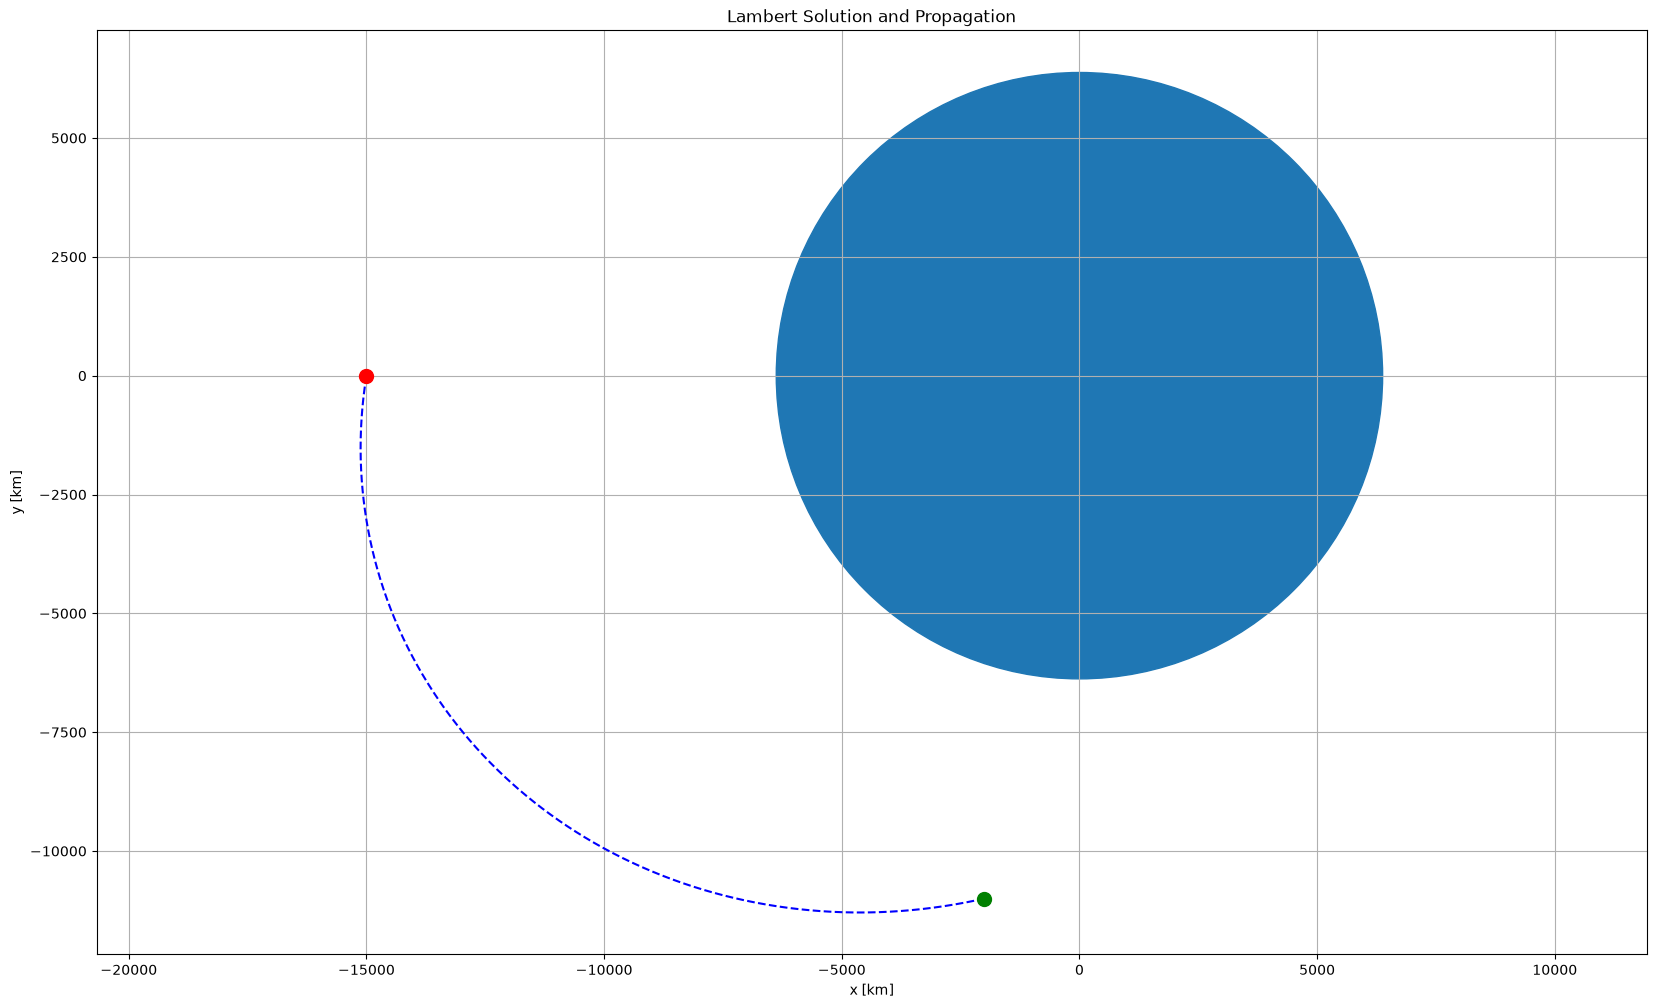

In [29]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation')

# Trajectory
ax.plot(sol[0], sol[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part c

In [30]:
def two_body_with_J2(t,x,mu=MU_EARTH, j2=J2_EARTH):
    state_dot = two_body(t,x,mu)
    
    norm_r = norm(x[0:3])
    r_hat = x[0:3] / norm_r
    k_hat = np.array([0,0,1])
    z = x[2]
    
    a_J2 = -(mu*j2*R_EARTH*R_EARTH/2) * (
        6*z/norm_r**5 * k_hat +
        (3/norm_r**4 - 15*z*z/norm_r**6) * r_hat
    )
    state_dot[3:6] += a_J2
    return state_dot

sol_J2: np.ndarray = solve_ivp(two_body_with_J2, (0, tof), np.concatenate((r1, v1)), method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y

In [31]:
print(f"Final r value [km]: \n\t{sol_J2[0:3, -1]}")
print(f"Goal r value [km]: \n\t{r2}")
print(f"Err [km]:\n\t{r2-sol_J2[0:3,-1]}")

Final r value [km]: 
	[ -1994.11058014 -10995.388839        0.        ]
Goal r value [km]: 
	[ -2000 -11000      0]
Err [km]:
	[-5.88941986 -4.611161    0.        ]


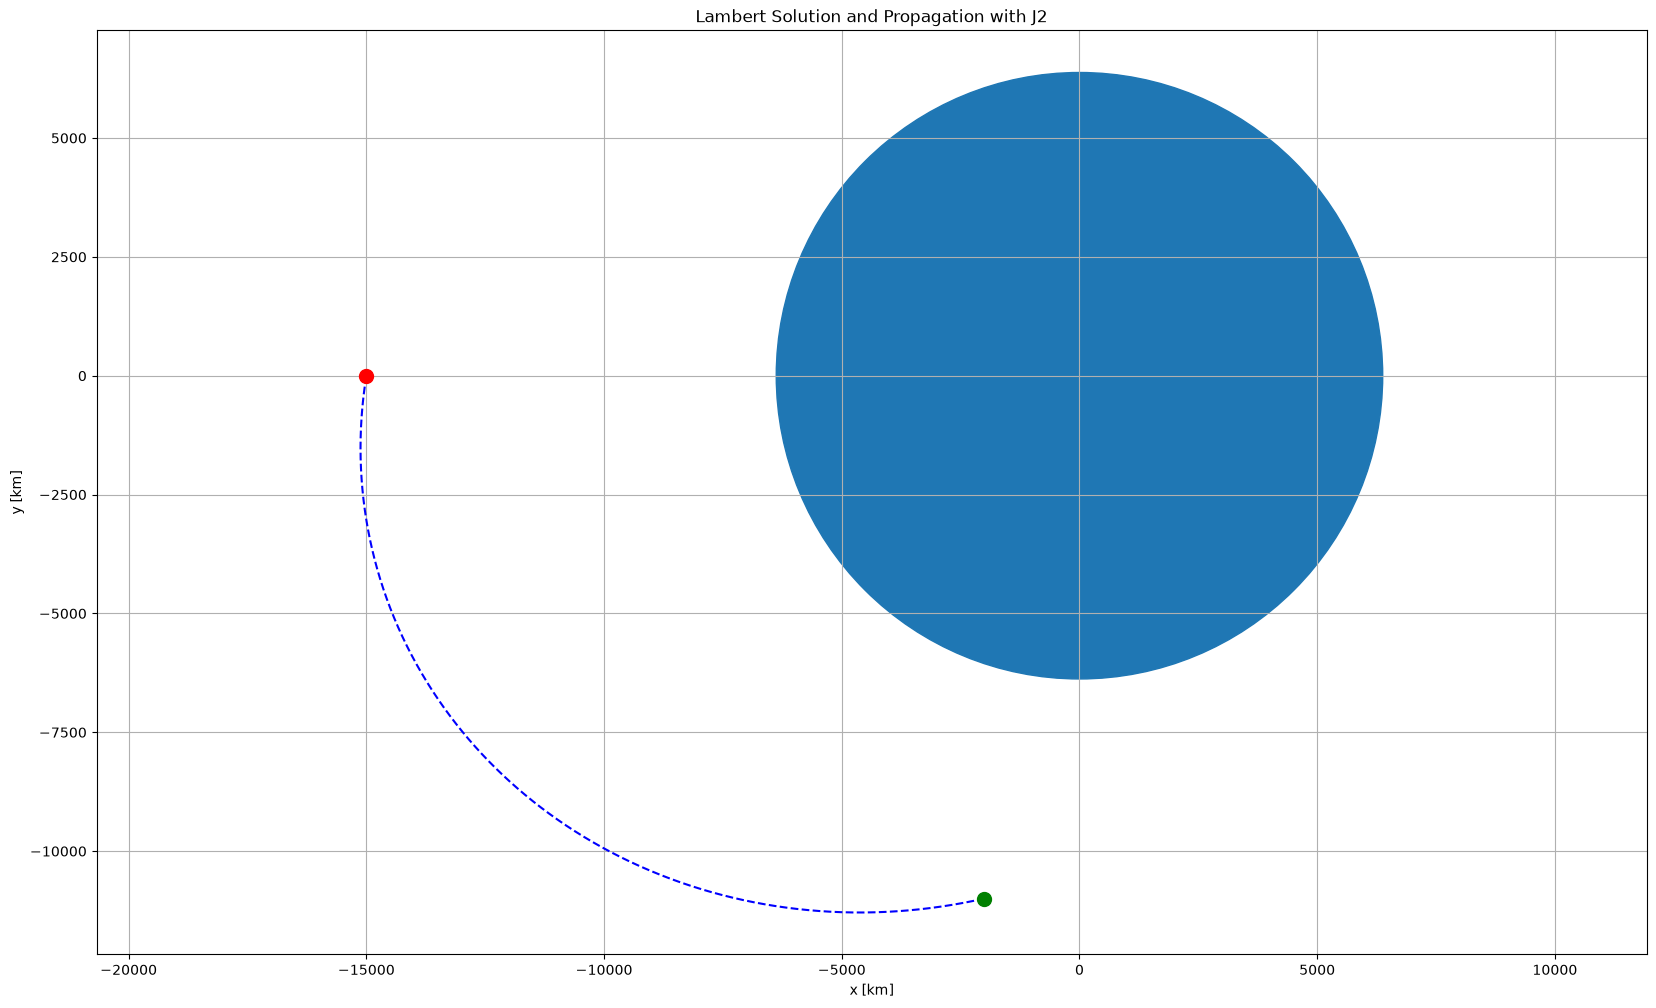

In [32]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation with J2')

# Trajectory
ax.plot(sol_J2[0], sol_J2[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part d

In [33]:
def AA279jacobianshoot(odefun, tspan, y0in, dv, t_arr):
    """
    Returns 3x3 Jacobian for shooting method

    AA279 Function Library
    Last modified: 7 October 2026 by Andrew K. Barrows

    Jacobian describes sensitivity of final position to initial velocity

    State must be of the form [rx ry rz vx vy vz]'

    sample function call:
    J = jacobianshoot(@earthorbitbody, [0; 75*60], [r1; v1], 0.001)

    odefun function handle for state derivative function
    tspan trajectory start and end times [sec]
    y0in state at which J should be evaluated
    dv small velocity increment used for finite differences
    t_arr array to be evaluated at
    
    """

    J = np.zeros((3,3))
    y0in = np.asarray(y0in)

    # vx
    y0 = y0in + [0,0,0,dv,0,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rhigh = sol.y[0:3, -1]
    y0 = y0in + [0,0,0,-dv,0,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rlow = sol.y[0:3, -1]
    J[:, 0] = (rhigh-rlow)/(2*dv)

    # vx
    y0 = y0in + [0,0,0,0,dv,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rhigh = sol.y[0:3, -1]
    y0 = y0in + [0,0,0,0,-dv,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rlow = sol.y[0:3, -1]
    J[:, 1] = (rhigh-rlow)/(2*dv)

    # vx
    y0 = y0in + [0,0,0,0,0,dv]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rhigh = sol.y[0:3, -1]
    y0 = y0in + [0,0,0,0,0,-dv]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rlow = sol.y[0:3, -1]
    J[:, 2] = (rhigh-rlow)/(2*dv)

    return J

In [34]:
def find_initial_conditions(t_arr, ode, state0, r_goal, iter = 10, convergence_bound = 10e-5, verbose = False):
    """10 cm bound"""

    
    tof = t_arr[-1]
    
    state = state0
    
    for i in range(iter):
        sim = solve_ivp(ode, (0, tof), state, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y
        
        dr = sim[0:3,-1] - r_goal
        dr_norm = norm(dr)
        
        if verbose:
            print(f"dr: {dr_norm:.5f}km")
        
        if norm(dr) < convergence_bound:
            print(f"\nConverged in {i} iterations with:\n\tdr = {dr_norm:.5e} km")
            break
        
        J = AA279jacobianshoot(ode, (0, tof), state, dv=0.001, t_arr=t_arr)
        
        # Only adjusting velocity
        state[3:6] -= np.linalg.pinv(J) @ dr

    return state

state0_one_update = find_initial_conditions(t_arr, two_body_with_J2, np.concatenate((r1, v1)), r2, 1)
v1_one_update = state0_one_update[3:6]

In [35]:
print(f"Old v1 value [km]: \n\t{v1}")
print(f"Final v1 value [km]: \n\t{v1_one_update}")
print(f"Difference [km]:\n\t{v1-v1_one_update}")

Old v1 value [km]: 
	[-0.65513692 -4.06361027  0.        ]
Final v1 value [km]: 
	[-6.55880979e-01 -4.06399725e+00  5.80741636e-31]
Difference [km]:
	[ 7.44054505e-04  3.86975119e-04 -5.80741636e-31]


### Part e

In [36]:
sol_one_update: np.ndarray = solve_ivp(two_body_with_J2, (0, tof), state0_one_update, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y

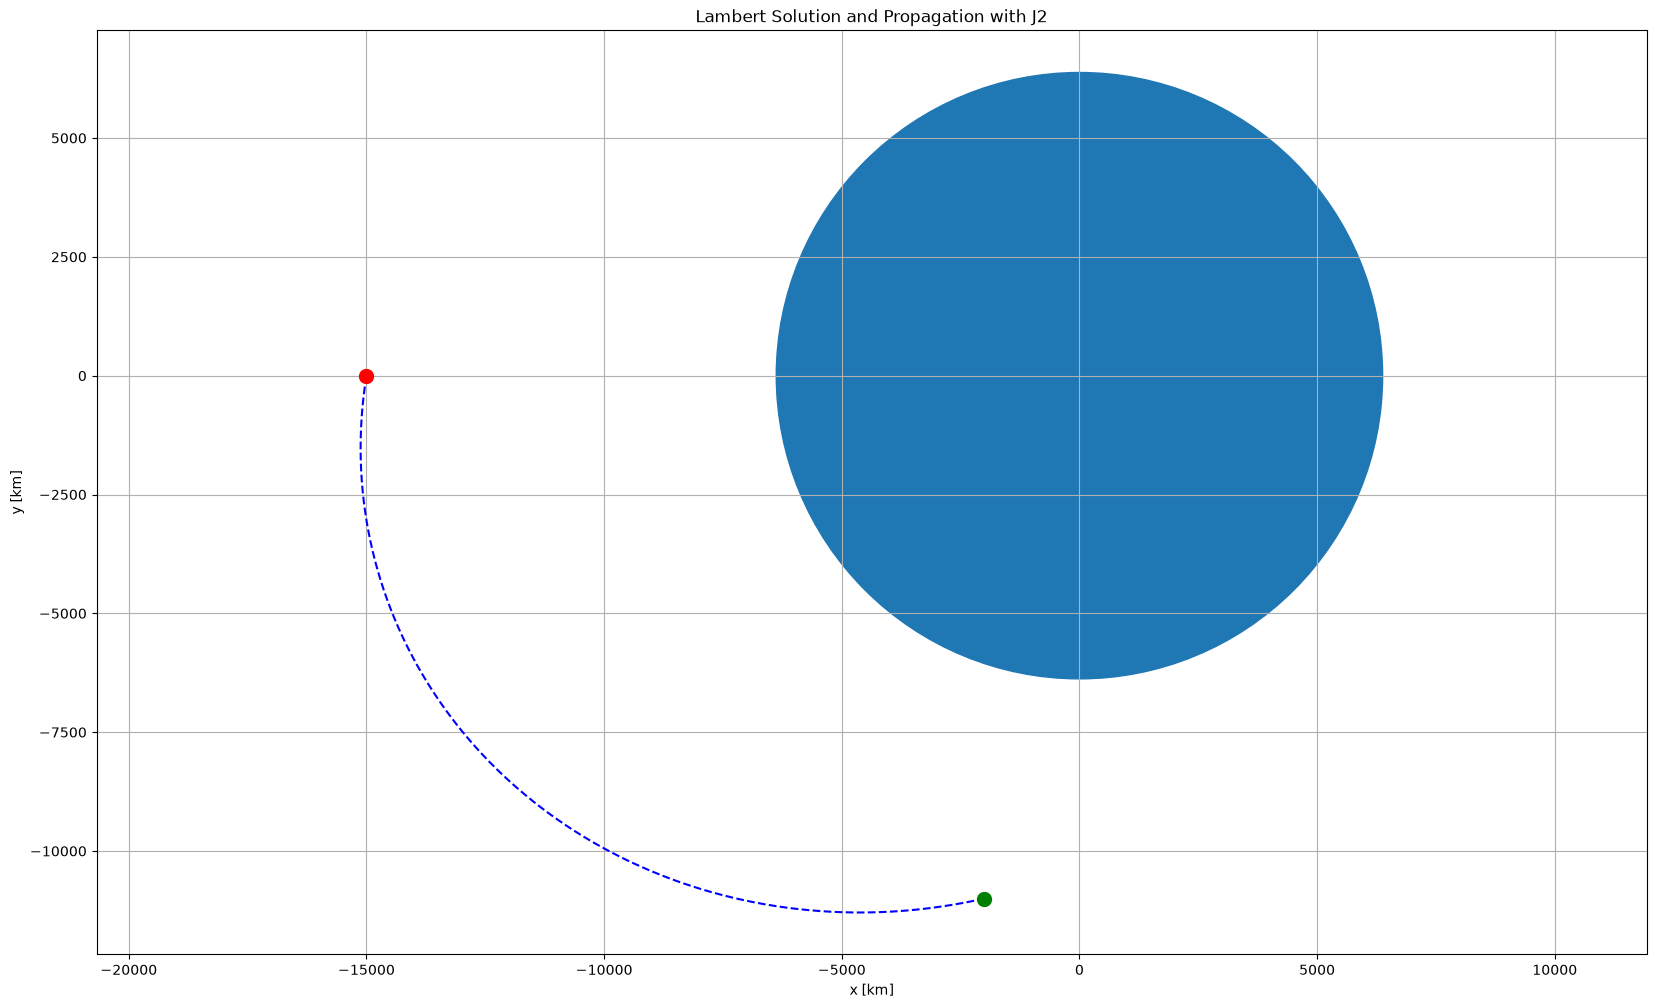

In [37]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation with J2')

# Trajectory
ax.plot(sol_one_update[0], sol_one_update[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part f

In [38]:
state0_full_updated = find_initial_conditions(t_arr, two_body_with_J2, np.concatenate((r1, v1)), r2)
v1_full_updated = state0_full_updated[3:6]


Converged in 3 iterations with:
	dr = 8.98310e-11 km


In [39]:
print(f"One-step v1 value [km]: \n\t{v1_one_update}")
print(f"Final Updated v1 value [km]: \n\t{v1_full_updated}")
print()
print(f"Difference [km]:\n\t{v1_one_update-v1_full_updated}")

One-step v1 value [km]: 
	[-6.55880979e-01 -4.06399725e+00  5.80741636e-31]
Final Updated v1 value [km]: 
	[-6.55880936e-01 -4.06399751e+00  5.40032976e-34]

Difference [km]:
	[-4.34170663e-08  2.62738334e-07  5.80201603e-31]


## Problem 3.3

In [40]:
SIDEREAL_HOUR_TO_SEC = 3590.1704167
DAY_TO_SEC = 24 * 60 * 60

DEG_TO_RAD = np.pi/180.0
RAD_TO_DEG = 1/DEG_TO_RAD



In [ ]:
# 00:00 Jan 1 2024, UTC
theta_gst = 6.7045617 * SIDEREAL_HOUR_TO_SEC

# Launcher data
launcher_lon = -122.081944 * DEG_TO_RAD
launcher_lat = 37.389444 * DEG_TO_RAD

# Dove 3 Orbital Elements
t0 = 21.68857885 * DAY_TO_SEC
i = 97.7791 * DEG_TO_RAD
raan = 95.3093 * DEG_TO_RAD
e = 0.0155616
aop = 357.8679 * DEG_TO_RAD
M = 2.1812 * DEG_TO_RAD
n = 14.56715041 / DAY_TO_SEC * 2 * np.pi # rev/day --> rad/s